# AutoPilotRL — v6: parking with SAC and Hindsight Experience Replay

## Where we are
**Highway (v1–v4, 5 discrete actions):** the attention Double Dueling DQN of v4 reached a return of 26.83 (rule-based driver: 22.83), at 28.5 m/s and with a 10% crash rate.

**Racetrack (v5, continuous steering):**

| Driver | Return | Finished | Crash |
|---|---|---|---|
| lane keeper (cheats) | 71.3 | 4% | 96% |
| REINFORCE | 97.0 | 62% | 38% |
| **PPO** | **133.4** | **80%** | 16% |

## v6: park the car
The last task is the hardest to solve by chance:
- the agent controls **throttle and steering**, 2 continuous actions;
- it starts in the middle of a parking lot, **standing still and pointing in a random direction**;
- it must stop inside a **parking spot that changes in every episode**, and with the right orientation.

### A goal-conditioned task
The policy receives the goal as part of its input: $\pi(a \mid s, g)$. One network must learn to reach **any** spot, not a single one.

### Why random exploration is not enough
- Success means being within about 1 m and 20° of the goal, while almost stopped.
- With random actions this practically never happens, so the agent almost never sees what success looks like.

### The two ideas of v6
1. **SAC** (Soft Actor-Critic, Haarnoja et al., 2018).
   - An actor-critic for continuous actions that, like DQN, is **off-policy**: it learns from a replay buffer of old experience.
   - It explores by maximising reward **plus entropy**.
   - It uses two critics and takes their minimum, the same anti-overestimation idea as Double DQN in v4.
2. **HER** (Hindsight Experience Replay, Andrychowicz et al., 2017).
   - An episode that missed spot $g$ still shows perfectly how to reach **the place where the car actually went**.
   - We store it a second time with that place as the goal, so every failure becomes a success for another goal.
   - This only works with an off-policy algorithm, which is why SAC and not PPO.

We train **SAC alone and SAC + HER**, with the same settings, to measure what HER adds.

## Plan
1. The environment, the goal and the reward.
2. Baselines: random actions and standing still.
3. The SAC networks: squashed Gaussian actor and twin critics.
4. The replay buffer with hindsight relabelling.
5. Training: SAC, then SAC + HER (40,000 steps each).
6. Learning curves, test on 50 scenarios, trajectories in the parking lot, GIFs.

Running time: about **25–40 minutes** on the CPU (the training cell prints an estimate). Run everything with **Run All**.

In [1]:
# --- LIBRARIES ---

# Gymnasium: the standard interface for RL environments.
import gymnasium as gym

# Registers the highway-env environments (including the parking).
import highway_env

# Numerical computing.
import numpy as np

# PyTorch: tensors and neural networks.
import torch

# Neural network layers.
import torch.nn as nn

# Loss functions.
import torch.nn.functional as F

# Probability distributions.
from torch.distributions import Normal

# Plotting.
import matplotlib.pyplot as plt

# Rectangles for the parking lot picture.
from matplotlib.patches import Rectangle

# Build GIF animations from frames.
from PIL import Image as PILImage

# Show images and GIFs in the notebook.
from IPython.display import Image, display

# Independent copies of networks (targets, best model).
import copy

# File and folder paths.
from pathlib import Path

# Results file.
import json

# Measure time.
import time

# Folder for the videos.
VIDEO_DIR = Path("videos")

# Create it if needed.
VIDEO_DIR.mkdir(exist_ok=True)

# Folder for the results and the trained models.
RESULTS_DIR = Path("results")

# Create it if needed.
RESULTS_DIR.mkdir(exist_ok=True)

# The parking environment.
ENV_NAME = "parking-v0"

# Small networks, simulator on the CPU: the CPU is the fastest choice here.
device = torch.device("cpu")

# Reproducibility for PyTorch.
torch.manual_seed(0)

# Versions.
print(f"torch {torch.__version__} | gymnasium {gym.__version__}")

torch 2.14.1 | gymnasium 1.4.0


## Step 1 — The environment, the goal and the reward

### Observation
The observation is a **dictionary** with three vectors of 6 numbers, $(x, y, v_x, v_y, \cos\psi, \sin\psi)$, divided by the scales $(100, 100, 5, 5, 1, 1)$:
- `observation`: the state of our car;
- `achieved_goal`: the same vector, the "goal" the car is achieving right now;
- `desired_goal`: the same features for the parking spot (position, zero speed, orientation of the spot).

Having `achieved_goal` and `desired_goal` in the same format is exactly what HER needs: any achieved goal can be used as a desired goal.

### Action
The action is $a = (\text{acceleration}, \text{steering}) \in [-1, 1]^2$, mapped to $\pm 5$ m/s² and $\pm 45°$. Negative acceleration means braking, and then reversing.

### Reward
The reward is the weighted distance between achieved and desired goal, with a square root:

$$r(s, g) = -\Big(\sum_i w_i\, |s_i - g_i|\Big)^{1/2} \;-\; 5 \cdot \text{crashed}, \qquad w = (1, 0.3, 0, 0, 0.02, 0.02)$$

- Position counts most: $x$ more than $y$, because the spots are narrow in $x$.
- Speed does not count directly.
- Orientation counts a little, through $\cos\psi$ and $\sin\psi$.
- The square root makes the reward rise steeply near the goal.
- Hitting a wall costs $-5$ and ends the episode.

### Success and end of the episode
- **Success** when $\big(\sum_i w_i |s_i - g_i|\big)^{1/2} < 0.12$: within roughly 1 m in $x$ and 20° in orientation. The episode ends (terminated).
- **Crash** into a wall: the episode ends (terminated).
- **Time limit**: 20 s = 100 decisions at 5 Hz (truncated). The default is 100 s; 20 s is enough to reach any spot and keeps training fast.

Because the reward can be computed from `(achieved_goal, desired_goal)` alone, we write our own vectorised copy of it, `goal_reward`, and check that it gives the same number as the environment. HER needs it to recompute rewards for new goals.

In [2]:
# --- ENVIRONMENTS ---

# The only change to the defaults: episodes of 20 seconds (100 decisions) instead of 100.
ENV_CONFIG = {"duration": 20}

# Training environment.
env = gym.make(ENV_NAME, config=ENV_CONFIG)

# Evaluation environment.
env_eval = gym.make(ENV_NAME, config=ENV_CONFIG)

# Video environment.
env_render = gym.make(ENV_NAME, render_mode="rgb_array", config=ENV_CONFIG)

# The settings that matter for us.
for key in ["duration", "policy_frequency", "reward_weights", "success_goal_reward", "collision_reward", "steering_range"]:

    # One line per setting.
    print(f"{key:<20} {env.unwrapped.config[key]}")

# Weights of the reward.
REWARD_WEIGHTS = np.array(env.unwrapped.config["reward_weights"])

# Success threshold.
SUCCESS_THRESHOLD = env.unwrapped.config["success_goal_reward"]

# Penalty for a crash.
COLLISION_REWARD = env.unwrapped.config["collision_reward"]

# Decisions per second.
POLICY_HZ = env.unwrapped.config["policy_frequency"]

# Size of each vector of the observation.
OBS_DIM = env.observation_space["observation"].shape[0]

# Number of actions (acceleration, steering).
ACT_DIM = env.action_space.shape[0]

# Spaces.
print("\nAction space:", env.action_space)


# The goal part of the reward, for one goal or a whole batch of goals.
def goal_reward(achieved, desired):
    """-(sum_i w_i |achieved_i - desired_i|) ** 0.5, along the last axis."""

    # Weighted L1 distance, then square root, with a minus sign.
    return -np.power(np.abs(achieved - desired) @ REWARD_WEIGHTS, 0.5)


# One episode start.
obs, info = env.reset(seed=0)

# Show the three vectors.
for key in ["observation", "achieved_goal", "desired_goal"]:

    # Rounded.
    print(f"{key:<14} {np.round(obs[key], 3)}")

# One step: a little acceleration, straight wheel.
obs, reward, terminated, truncated, info = env.step(np.array([0.3, 0.0], dtype=np.float32))

# The environment's reward and ours must match.
print(f"\nReward from the environment: {reward:.4f} | our goal_reward: {goal_reward(obs['achieved_goal'], obs['desired_goal']):.4f}")

# Success flag.
print("is_success:", info["is_success"])

duration             20
policy_frequency     5
reward_weights       [1, 0.3, 0, 0, 0.02, 0.02]
success_goal_reward  0.12
collision_reward     -5
steering_range       0.7853981633974483

Action space: Box(-1.0, 1.0, (2,), float32)
observation    [ 0.     0.    -0.    -0.    -0.652 -0.758]
achieved_goal  [ 0.     0.    -0.    -0.    -0.652 -0.758]
desired_goal   [0.26 0.14 0.   0.   0.   1.  ]

Reward from the environment: -0.5919 | our goal_reward: -0.5919
is_success: False


## Step 2 — Evaluation and baselines

### The test protocol
As before: **50 fixed test scenarios** (seeds 1000–1049), validation on seeds 2000–2009, and training from seed 10,000. The seed fixes the starting orientation of the car and the target spot.

For each episode we measure:
- the **return** (negative: closer to 0 is better);
- **success** (parked), **crash** (hit a wall), or neither (time is up);
- the **time** taken, in seconds;
- the final **distance** to the centre of the spot (metres) and the final **heading error** (degrees).

### Baselines
- **Random:** random acceleration and steering.
- **Standing still:** no acceleration, no steering. The car never moves: its return is the cost of the starting distance, paid for 100 steps.

There is no simple hand-written controller this time. Parking needs planning (where to turn, when to reverse), which is exactly what we want the agent to learn.

random          return  -33.99 | success   0% | crash  84% | time 13.0 s | final distance 27.79 m | heading error  95.3 deg
standing still  return  -46.78 | success   0% | crash   0% | time 20.2 s | final distance 20.81 m | heading error  95.0 deg
Random, scenario 1000: return -35.73, time up  (videos/v6_random.gif)


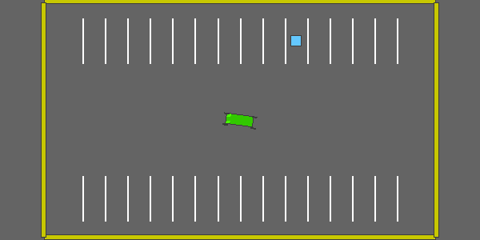

In [3]:
# --- EVALUATION ---

# The 50 fixed test scenarios.
EVAL_SEEDS = list(range(1000, 1050))

# Validation scenarios.
VAL_SEEDS = list(range(2000, 2010))


# Run a policy on a list of scenarios and measure it.
def evaluate(policy, seeds=EVAL_SEEDS, env=env_eval):
    """policy(env, obs_dict) -> action of shape (2,). Returns a dict of per-episode arrays."""

    # Per-episode measurements.
    returns, successes, crashes, times, distances, heading_errors = [], [], [], [], [], []

    # One episode per seed.
    for seed in seeds:

        # Start the episode.
        obs, info = env.reset(seed=seed)

        # Return and steps.
        episode_return, steps = 0.0, 0

        # Until the end.
        done = False

        # Play.
        while not done:

            # One decision.
            obs, reward, terminated, truncated, info = env.step(policy(env, obs))

            # Accumulate the reward.
            episode_return += reward

            # Count.
            steps += 1

            # End?
            done = terminated or truncated

        # Our car and its goal.
        vehicle = env.unwrapped.vehicle

        # Store the return.
        returns.append(episode_return)

        # Parked?
        successes.append(bool(info["is_success"]))

        # Hit a wall?
        crashes.append(bool(vehicle.crashed))

        # Seconds used.
        times.append(steps / POLICY_HZ)

        # Distance from the centre of the spot.
        distances.append(np.linalg.norm(vehicle.position - vehicle.goal.position))

        # Heading difference, wrapped into [-pi, pi], in degrees.
        heading_errors.append(np.degrees(abs((vehicle.heading - vehicle.goal.heading + np.pi) % (2 * np.pi) - np.pi)))

    # Everything as NumPy arrays.
    return {"return": np.array(returns), "success": np.array(successes, dtype=float),
            "crash": np.array(crashes, dtype=float), "time": np.array(times),
            "distance": np.array(distances), "heading_error": np.array(heading_errors)}


# One line summary of an evaluation.
def summary(name, res):
    """Print the mean of every metric."""

    # Means.
    print(f"{name:<15} return {res['return'].mean():7.2f} | success {res['success'].mean():4.0%} | "
          f"crash {res['crash'].mean():4.0%} | time {res['time'].mean():4.1f} s | "
          f"final distance {res['distance'].mean():5.2f} m | heading error {res['heading_error'].mean():5.1f} deg")


# --- VIDEOS ---

# Play one episode with rendering and save it as a GIF.
def record_episode(policy, seed, filename, env=env_render, size=(480, 240)):
    """Return (path of the GIF, return of the episode, outcome)."""

    # Start the episode.
    obs, info = env.reset(seed=seed)

    # First frame, reduced in size.
    frames = [PILImage.fromarray(env.render()).resize(size)]

    # Return of the episode.
    episode_return = 0.0

    # Until the end.
    done = False

    # Play.
    while not done:

        # One decision.
        obs, reward, terminated, truncated, info = env.step(policy(env, obs))

        # Accumulate the reward.
        episode_return += reward

        # One frame per decision.
        frames.append(PILImage.fromarray(env.render()).resize(size))

        # End?
        done = terminated or truncated

    # How it ended.
    outcome = "PARKED" if info["is_success"] else ("CRASH" if env.unwrapped.vehicle.crashed else "time up")

    # Path of the GIF.
    path = VIDEO_DIR / filename

    # 100 ms per frame = twice real time; loop forever.
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=100, loop=0)

    # Path, return and outcome.
    return path, episode_return, outcome


# Record an episode and show it in the notebook.
def show_episode(policy, seed, filename, title, env=env_render):
    """Save the GIF, print the outcome and display the animation."""

    # Record it.
    path, episode_return, outcome = record_episode(policy, seed, filename, env=env)

    # Outcome.
    print(f"{title}: return {episode_return:.2f}, {outcome}  ({path})")

    # The animation.
    display(Image(filename=str(path)))


# --- BASELINES ---

# Random generator for the random driver.
rng = np.random.default_rng(0)


# Random acceleration and steering.
def random_driver(env, obs):
    """Uniform in [-1, 1]^2."""

    # Two random numbers.
    return rng.uniform(-1, 1, size=ACT_DIM).astype(np.float32)


# Do nothing.
def still_driver(env, obs):
    """Zero acceleration, zero steering."""

    # Two zeros.
    return np.zeros(ACT_DIM, dtype=np.float32)


# All test results, by driver name.
results = {}

# Evaluate the baselines.
for name, driver in [("random", random_driver), ("standing still", still_driver)]:

    # 50 test scenarios.
    results[name] = evaluate(driver)

    # Report.
    summary(name, results[name])

# The random driver on the usual scenario.
show_episode(random_driver, seed=1000, filename="v6_random.gif", title="Random, scenario 1000")

## Step 3 — SAC: Soft Actor-Critic

### Maximum entropy objective
SAC maximises the reward **plus the entropy** of the policy:

$$J(\pi) = \sum_t \mathbb{E}\Big[r_t + \alpha\, \mathcal{H}\big(\pi(\cdot \mid s_t)\big)\Big], \qquad \mathcal{H}(\pi(\cdot \mid s)) = \mathbb{E}_{a \sim \pi}\big[-\log \pi(a \mid s)\big]$$

The agent is paid for staying random where it does not matter. Exploration is part of the objective, and its weight $\alpha$ (the *temperature*) is tuned automatically (see below).

### The squashed Gaussian actor
The actions must stay in $[-1, 1]$, so the actor samples from a Gaussian and squashes with `tanh`:

$$u = \mu_\theta(s) + \sigma_\theta(s) \odot \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, I), \qquad a = \tanh(u)$$

- Unlike v5, $\sigma$ now depends on the state: the agent can be precise near the spot and loose far from it.
- `tanh` changes the density, so the log-probability needs a correction (change of variables):

$$\log \pi(a \mid s) = \log \mathcal{N}(u;\, \mu, \sigma^2) - \sum_i \log\big(1 - \tanh^2(u_i)\big)$$

- **Reparameterisation trick:** writing $a$ as a function of $\theta$ and of the noise $\varepsilon$ lets the gradient flow from the critic, through the action, into the actor. In v5 we only had $\nabla \log \pi$.
- For evaluation we drive deterministically: $a = \tanh(\mu_\theta(s))$.

### Twin critics and the soft Bellman target
Two Q-networks $Q_1, Q_2$, each with a slowly moving **target copy** $\bar{Q}_1, \bar{Q}_2$. The target uses the **minimum** of the two, against overestimation (like Double DQN in v4), and includes the entropy bonus of the next action:

$$y = r + \gamma\,(1 - d)\Big(\min_{j=1,2} \bar{Q}_j(s', a') - \alpha \log \pi(a' \mid s')\Big), \qquad a' \sim \pi(\cdot \mid s')$$

$$\mathcal{L}_Q = \big(Q_1(s, a) - y\big)^2 + \big(Q_2(s, a) - y\big)^2$$

### Actor loss
Choose actions with a high Q-value, but stay random:

$$\mathcal{L}_\pi = \mathbb{E}_{s,\, \varepsilon}\Big[\alpha \log \pi(a \mid s) - \min_j Q_j(s, a)\Big], \qquad a = \tanh(\mu_\theta(s) + \sigma_\theta(s)\,\varepsilon)$$

### Automatic temperature
$\alpha$ is adjusted so that the entropy stays near a target $\bar{\mathcal{H}} = -\dim(\mathcal{A}) = -2$:

$$\mathcal{L}_\alpha = -\log\alpha \cdot \mathbb{E}\big[\log \pi(a \mid s) + \bar{\mathcal{H}}\big]$$

If the policy is less random than the target, $\alpha$ grows (more reward for entropy), and vice versa.

### Target networks: Polyak averaging
Instead of copying every N steps (as in DQN), after each update the targets move a little towards the online critics:

$$\bar{\phi} \leftarrow (1 - \tau)\,\bar{\phi} + \tau\,\phi, \qquad \tau = 0.05$$

### Input of the networks
The input is the observation and the desired goal, concatenated: 12 numbers. Positions were divided by 100 by the environment, so the spots are within about ±0.3. We multiply positions by 10 so the inputs are of order 1.

| Setting | Value |
|---|---|
| Hidden layers | 256 × 256, ReLU (actor and each critic) |
| Discount γ | 0.95 (horizon of about 4 s at 5 Hz: parking is a short task) |
| Learning rate | 1e-3 (actor, critics, α) |
| Batch size | 256 |
| τ | 0.05 |
| Target entropy | −2 |

In [4]:
# --- SAC NETWORKS ---

# Width of the hidden layers.
HIDDEN = 256

# Network input: observation (6) + desired goal (6).
IN_DIM = 2 * OBS_DIM

# Positions x, y are multiplied by 10 (they arrive divided by 100); the other features stay as they are.
INPUT_SCALE = np.array([10, 10, 1, 1, 1, 1] * 2, dtype=np.float32)


# Build the network input from observations and goals (single vectors or batches).
def make_input(observation, goal):
    """Concatenate along the last axis and rescale -> float32 tensor."""

    # Concatenate.
    x = np.concatenate([observation, goal], axis=-1) * INPUT_SCALE

    # As a tensor.
    return torch.as_tensor(x, dtype=torch.float32)


# Multilayer perceptron with two hidden ReLU layers.
def mlp(in_dim, out_dim, hidden=HIDDEN):
    """in -> hidden -> hidden -> out."""

    # The layers in sequence.
    return nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, out_dim))


# Actor: input -> tanh-squashed Gaussian action.
class SquashedGaussianActor(nn.Module):
    """Mean and log-std depend on the state; a = tanh(mean + std * eps)."""

    # Build the layers.
    def __init__(self, in_dim=IN_DIM, act_dim=ACT_DIM, hidden=HIDDEN):

        # Initialise nn.Module.
        super().__init__()

        # Shared body.
        self.body = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU())

        # Mean of u.
        self.mean_head = nn.Linear(hidden, act_dim)

        # Log standard deviation of u.
        self.log_std_head = nn.Linear(hidden, act_dim)

    # Sample an action (or the deterministic one) and its log-probability.
    def forward(self, x, deterministic=False):
        """x: (B, IN_DIM) -> actions (B, ACT_DIM), log_prob (B,) or None."""

        # Hidden features.
        h = self.body(x)

        # Mean.
        mean = self.mean_head(h)

        # Log-std, kept in a safe range.
        log_std = self.log_std_head(h).clamp(-20, 2)

        # Deterministic action for evaluation.
        if deterministic:

            # Squash the mean.
            return torch.tanh(mean), None

        # Gaussian over u.
        dist = Normal(mean, log_std.exp())

        # Reparameterised sample: mean + std * eps (gradients flow through it).
        u = dist.rsample()

        # Squash into [-1, 1].
        action = torch.tanh(u)

        # log N(u) minus the tanh correction, summed over the action dimensions.
        log_prob = dist.log_prob(u).sum(dim=1) - torch.log(1 - action.pow(2) + 1e-6).sum(dim=1)

        # Action and its log-probability.
        return action, log_prob


# Critic: (input, action) -> Q-value.
class QNet(nn.Module):
    """Q(s, g, a)."""

    # Build the layers.
    def __init__(self, in_dim=IN_DIM, act_dim=ACT_DIM):

        # Initialise nn.Module.
        super().__init__()

        # One MLP on the concatenation of state-goal and action.
        self.net = mlp(in_dim + act_dim, 1)

    # Forward pass.
    def forward(self, x, action):
        """-> (B,)."""

        # Concatenate and evaluate.
        return self.net(torch.cat([x, action], dim=1)).squeeze(-1)


# Discount factor.
GAMMA = 0.95

# Learning rate.
LR = 1e-3

# Polyak coefficient of the target networks.
TAU = 0.05

# Target entropy: minus the number of action dimensions.
TARGET_ENTROPY = -float(ACT_DIM)


# Everything SAC needs: actor, twin critics, their targets, temperature, optimisers.
class SACAgent:
    """One SAC learner."""

    # Create the networks and optimisers.
    def __init__(self):

        # Actor.
        self.actor = SquashedGaussianActor()

        # Twin critics.
        self.q1, self.q2 = QNet(), QNet()

        # Their target copies.
        self.q1_target, self.q2_target = copy.deepcopy(self.q1), copy.deepcopy(self.q2)

        # Log of the temperature (alpha = 1 at the start).
        self.log_alpha = torch.zeros(1, requires_grad=True)

        # Actor optimiser.
        self.actor_opt = torch.optim.Adam(self.actor.parameters(), lr=LR)

        # One optimiser for both critics.
        self.critic_opt = torch.optim.Adam(list(self.q1.parameters()) + list(self.q2.parameters()), lr=LR)

        # Temperature optimiser.
        self.alpha_opt = torch.optim.Adam([self.log_alpha], lr=LR)

    # Current temperature.
    @property
    def alpha(self):
        """exp(log_alpha) as a plain number."""

        # As a float.
        return self.log_alpha.exp().item()

    # Choose an action for one observation.
    @torch.no_grad()
    def act(self, observation, goal, deterministic=False):
        """-> NumPy array (ACT_DIM,)."""

        # Action for a batch of one.
        action, _ = self.actor(make_input(observation, goal).unsqueeze(0), deterministic=deterministic)

        # As NumPy.
        return action[0].numpy()

    # One SAC update on a batch.
    def update(self, x, action, reward, x_next, done):
        """All tensors with batch dimension first. Returns the critic loss."""

        # Current temperature, as a constant.
        alpha = self.log_alpha.exp().detach()

        # --- Critics ---
        with torch.no_grad():

            # Next action and its log-probability, from the current policy.
            next_action, next_log_prob = self.actor(x_next)

            # Pessimistic target value, with the entropy bonus.
            next_q = torch.min(self.q1_target(x_next, next_action), self.q2_target(x_next, next_action)) - alpha * next_log_prob

            # Soft Bellman target (no bootstrap after a terminal transition).
            y = reward + GAMMA * (1.0 - done) * next_q

        # Both critics regress towards the same target.
        critic_loss = F.mse_loss(self.q1(x, action), y) + F.mse_loss(self.q2(x, action), y)

        # Clear the old gradients.
        self.critic_opt.zero_grad()

        # Backpropagation.
        critic_loss.backward()

        # Update the critics.
        self.critic_opt.step()

        # --- Actor ---
        # Fresh reparameterised actions for the same states.
        new_action, log_prob = self.actor(x)

        # Value of those actions according to the (pessimistic) critics.
        q_new = torch.min(self.q1(x, new_action), self.q2(x, new_action))

        # High Q, but stay random.
        actor_loss = (alpha * log_prob - q_new).mean()

        # Clear the old gradients.
        self.actor_opt.zero_grad()

        # Backpropagation (this also fills gradients in the critics: they are cleared before their next step).
        actor_loss.backward()

        # Update the actor.
        self.actor_opt.step()

        # --- Temperature ---
        alpha_loss = -(self.log_alpha * (log_prob.detach() + TARGET_ENTROPY)).mean()

        # Clear the old gradient.
        self.alpha_opt.zero_grad()

        # Backpropagation.
        alpha_loss.backward()

        # Update alpha.
        self.alpha_opt.step()

        # --- Targets: Polyak averaging ---
        with torch.no_grad():

            # Both critic pairs.
            for net, target in [(self.q1, self.q1_target), (self.q2, self.q2_target)]:

                # Every parameter.
                for p, p_target in zip(net.parameters(), target.parameters()):

                    # Move the target a little towards the online network.
                    p_target.mul_(1 - TAU).add_(TAU * p)

        # For the learning curves.
        return critic_loss.item()


# A quick check.
check_agent = SACAgent()

# Sizes.
print(f"Actor parameters: {sum(p.numel() for p in check_agent.actor.parameters()):,} | "
      f"each critic: {sum(p.numel() for p in check_agent.q1.parameters()):,}")

# Five stochastic actions for the first observation.
obs, _ = env.reset(seed=0)

# Show them.
print("Five random-ish actions:\n", np.round([check_agent.act(obs["observation"], obs["desired_goal"]) for _ in range(5)], 2))

Actor parameters: 70,148 | each critic: 69,889
Five random-ish actions:
 [[ 0.94 -0.4 ]
 [-0.98  0.56]
 [-0.99 -0.97]
 [-0.3  -0.95]
 [ 0.97 -0.38]]


## Step 4 — Replay buffer with Hindsight Experience Replay

### The idea
An episode tried to reach goal $g$ and failed: the car ended somewhere else. As an example of reaching $g$ the episode is useless (all rewards are bad). But it is a **perfect example of reaching the places the car actually visited**.

HER stores the same transitions again with a **different goal**: an achieved goal taken from **later in the same episode** (the *future* strategy):

$$(s_t, a_t, s_{t+1}, g) \;\longrightarrow\; (s_t, a_t, s_{t+1}, g'), \qquad g' = \text{achieved\_goal}(s_{t'}),\; t' \ge t+1$$

- The reward is recomputed for the new goal: $r' = r(s_{t+1}, g') - 5 \cdot \text{crashed}$.
- The transition is terminal if the car crashed, or if $s_{t+1}$ already **succeeds** for $g'$.

### Why this is allowed
- **The physics does not depend on the goal**: the same action from the same state leads to the same next state, whatever spot we had in mind. So the relabelled transition is a true transition of the environment.
- **SAC is off-policy**: it can learn from transitions that the current policy (aiming at $g$) did not collect "for" $g'$. PPO could not, because its ratio $\pi_\theta / \pi_{old}$ assumes the data was collected for the goal it is trained on.

### Implementation
- Episodes are stored **when they end**, so for every transition we know where its episode finishes (`ep_end`).
- At sampling time, each transition of the batch gets a future goal with probability **0.8**. This is the classic "k = 4" of the HER paper: 4 relabelled for 1 original, so 4 / 5 = 0.8.
- With probability 0 we get plain SAC: **the same code** serves both experiments.
- The buffer is big enough for all the steps of a run, so nothing is ever overwritten.

In [5]:
# --- REPLAY BUFFER WITH HER ---

# Probability of replacing the goal of a sampled transition with a future achieved goal.
HER_PROB = 0.8


# Stores whole episodes and relabels goals at sampling time.
class HERReplayBuffer:
    """Flat arrays of transitions + the index of the last transition of each one's episode."""

    # Allocate the arrays.
    def __init__(self, capacity):

        # Observation before the step.
        self.obs = np.zeros((capacity, OBS_DIM), dtype=np.float32)

        # Desired goal of the episode.
        self.goal = np.zeros((capacity, OBS_DIM), dtype=np.float32)

        # Action taken.
        self.action = np.zeros((capacity, ACT_DIM), dtype=np.float32)

        # Observation after the step.
        self.next_obs = np.zeros((capacity, OBS_DIM), dtype=np.float32)

        # Achieved goal after the step (the candidates for relabelling).
        self.achieved_next = np.zeros((capacity, OBS_DIM), dtype=np.float32)

        # Crashed at this step.
        self.crashed = np.zeros(capacity, dtype=np.float32)

        # Index of the last transition of the episode.
        self.ep_end = np.zeros(capacity, dtype=np.int64)

        # Number of stored transitions.
        self.size = 0

        # Its own random generator.
        self.rng = np.random.default_rng(0)

    # Store a finished episode.
    def add_episode(self, transitions):
        """transitions: list of (obs, goal, action, next_obs, achieved_next, crashed)."""

        # Where the episode starts in the arrays.
        start = self.size

        # Where it ends.
        end = start + len(transitions) - 1

        # Copy every transition.
        for i, (o, g, a, o2, ag2, c) in enumerate(transitions):

            # Position in the arrays.
            k = start + i

            # Observation.
            self.obs[k] = o

            # Goal.
            self.goal[k] = g

            # Action.
            self.action[k] = a

            # Next observation.
            self.next_obs[k] = o2

            # Achieved goal after the step.
            self.achieved_next[k] = ag2

            # Crash flag.
            self.crashed[k] = c

            # Last index of this episode.
            self.ep_end[k] = end

        # New size.
        self.size = end + 1

    # Sample a batch, relabelling goals with probability her_prob.
    def sample(self, batch_size, her_prob):
        """Returns tensors (x, action, reward, x_next, done)."""

        # Random transitions.
        idx = self.rng.integers(0, self.size, size=batch_size)

        # Their original goals (a copy: we are going to change some of them).
        goals = self.goal[idx].copy()

        # Which ones get a hindsight goal.
        relabel = self.rng.random(batch_size) < her_prob

        # A future step of the same episode for every transition (from t to the end, inclusive).
        future = self.rng.integers(idx, self.ep_end[idx] + 1)

        # Replace the goal with what the car achieved at that future step.
        goals[relabel] = self.achieved_next[future[relabel]]

        # Goal part of the reward, recomputed for the (possibly new) goals.
        goal_r = goal_reward(self.achieved_next[idx], goals)

        # Full reward, with the crash penalty.
        reward = goal_r + COLLISION_REWARD * self.crashed[idx]

        # Terminal: crash, or success for this goal.
        done = np.maximum(self.crashed[idx], (goal_r > -SUCCESS_THRESHOLD).astype(np.float32))

        # Tensors for the networks.
        return (make_input(self.obs[idx], goals), torch.as_tensor(self.action[idx]),
                torch.as_tensor(reward, dtype=torch.float32), make_input(self.next_obs[idx], goals),
                torch.as_tensor(done, dtype=torch.float32))

## Step 5 — Training: SAC alone, then SAC + HER

The loop, at every environment step:
1. Choose an action: **random** for the first 1,000 steps (to fill the buffer with varied data), then **sampled from the actor**.
2. Step the environment and keep the transition in the current episode.
3. One SAC update on a batch of 256 transitions from the buffer.
4. At the end of the episode, store it in the buffer.

Every 5,000 steps we validate on 10 scenarios (deterministic driving) and keep the weights with the best **success rate** (mean return as tie-breaker).

The two runs differ in **one number**: the relabelling probability, 0 for SAC and 0.8 for SAC + HER. Same seeds, same steps, same networks.

| Setting | Value |
|---|---|
| Environment steps per run | 40,000 |
| Random warm-up | 1,000 steps |
| Updates | 1 per environment step |
| Validation | every 5,000 steps, 10 scenarios |

In [6]:
# --- SAC TRAINING ---

# Environment steps per run.
TOTAL_STEPS = 40_000

# Random actions at the start.
WARMUP = 1_000

# Batch size.
BATCH_SIZE = 256

# Validate every this many steps.
VAL_EVERY = 5_000


# Turn an agent into a deterministic driver for evaluate().
def make_driver(agent):
    """driver(env, obs_dict) -> tanh(mean)."""

    # The driver function.
    def drive(env, obs):

        # Deterministic action for this observation and goal.
        return agent.act(obs["observation"], obs["desired_goal"], deterministic=True)

    # Return it.
    return drive


# Train one SAC agent.
def train_sac(her_prob, label):
    """Return (best agent, training log)."""

    # Same starting weights for both runs.
    torch.manual_seed(0)

    # The learner.
    agent = SACAgent()

    # Buffer for every step of the run.
    buffer = HERReplayBuffer(TOTAL_STEPS + 200)

    # Random generator for the warm-up actions.
    warmup_rng = np.random.default_rng(0)

    # Training log.
    log = {"episode_steps": [], "success": [], "return": [], "val_steps": [], "val_success": [],
           "alpha_steps": [], "alpha": [], "critic_loss": []}

    # Steps so far.
    steps = 0

    # Training scenarios.
    seed = 10_000

    # Best validation (success rate, mean return) and its weights.
    best_score, best_actor = (-1.0, -np.inf), None

    # Critic losses since the last log line.
    recent_losses = []

    # Clock.
    start = time.time()

    # Until the step budget is used.
    while steps < TOTAL_STEPS:

        # New training scenario.
        obs, info = env.reset(seed=seed)

        # Next scenario.
        seed += 1

        # Transitions of this episode.
        episode = []

        # Return of this episode.
        episode_return = 0.0

        # Until the end.
        done = False

        # Play.
        while not done:

            # Warm-up: random actions.
            if steps < WARMUP:

                # Uniform in [-1, 1]^2.
                action = warmup_rng.uniform(-1, 1, size=ACT_DIM).astype(np.float32)

            # Afterwards: the actor, with its exploration.
            else:

                # Stochastic action.
                action = agent.act(obs["observation"], obs["desired_goal"])

            # One step.
            next_obs, reward, terminated, truncated, info = env.step(action)

            # Keep the transition.
            episode.append((obs["observation"], obs["desired_goal"], action, next_obs["observation"],
                            next_obs["achieved_goal"], float(env.unwrapped.vehicle.crashed)))

            # Accumulate the reward.
            episode_return += reward

            # Move on.
            obs = next_obs

            # Count.
            steps += 1

            # End?
            done = terminated or truncated

            # One SAC update, once the buffer has enough data.
            if steps >= WARMUP and buffer.size >= BATCH_SIZE:

                # Learn from a (relabelled) batch.
                recent_losses.append(agent.update(*buffer.sample(BATCH_SIZE, her_prob)))

            # Every 1,000 steps: log alpha and the critic loss.
            if steps % 1000 == 0 and recent_losses:

                # Step.
                log["alpha_steps"].append(steps)

                # Temperature.
                log["alpha"].append(agent.alpha)

                # Mean critic loss.
                log["critic_loss"].append(np.mean(recent_losses))

                # Reset.
                recent_losses = []

            # Time estimate, once, after 500 updates.
            if steps == WARMUP + 500:

                # Milliseconds per step including the update.
                ms = (time.time() - start) / steps * 1000

                # Estimate (the warm-up steps are faster, so this is slightly optimistic).
                print(f"[{label}] about {ms:.1f} ms/step -> about {ms * TOTAL_STEPS / 60000:.0f} min for this run (plus validations)")

            # Time to validate?
            if steps % VAL_EVERY == 0:

                # Deterministic driving on the validation scenarios.
                val = evaluate(make_driver(agent), seeds=VAL_SEEDS)

                # Success rate and mean return.
                score = (val["success"].mean(), val["return"].mean())

                # Log.
                log["val_steps"].append(steps)

                # Success.
                log["val_success"].append(score[0])

                # Best so far?
                if score > best_score:

                    # Remember it.
                    best_score, best_actor = score, copy.deepcopy(agent.actor.state_dict())

                # Progress.
                print(f"[{label}] step {steps:6d} | train success (last 50 ep.) {np.mean(log['success'][-50:]):4.0%} | "
                      f"val success {score[0]:4.0%} | val return {score[1]:7.2f} | alpha {agent.alpha:.3f} | {time.time() - start:.0f}s")

        # Store the finished episode.
        buffer.add_episode(episode)

        # Log the episode.
        log["episode_steps"].append(steps)

        # Parked?
        log["success"].append(float(info["is_success"]))

        # Return.
        log["return"].append(episode_return)

    # Back to the best actor.
    agent.actor.load_state_dict(best_actor)

    # Report.
    print(f"[{label}] best validation: success {best_score[0]:.0%}, return {best_score[1]:.2f}\n")

    # The trained agent and the log.
    return agent, log


# Plain SAC: no relabelling.
sac_agent, sac_log = train_sac(her_prob=0.0, label="SAC")

# SAC + HER.
her_agent, her_log = train_sac(her_prob=HER_PROB, label="SAC+HER")

# Save both actors.
torch.save(sac_agent.actor.state_dict(), RESULTS_DIR / "v6_sac_actor.pt")

# SAC + HER actor.
torch.save(her_agent.actor.state_dict(), RESULTS_DIR / "v6_sac_her_actor.pt")

[SAC] about 6.1 ms/step -> about 4 min for this run (plus validations)
[SAC] step   5000 | train success (last 50 ep.)   2% | val success  10% | val return  -16.84 | alpha 0.023 | 39s
[SAC] step  10000 | train success (last 50 ep.)   8% | val success  20% | val return  -13.88 | alpha 0.004 | 85s
[SAC] step  15000 | train success (last 50 ep.)  18% | val success  10% | val return  -17.45 | alpha 0.005 | 132s
[SAC] step  20000 | train success (last 50 ep.)  42% | val success  20% | val return  -17.95 | alpha 0.006 | 176s
[SAC] step  25000 | train success (last 50 ep.)  40% | val success  70% | val return  -11.27 | alpha 0.006 | 218s
[SAC] step  30000 | train success (last 50 ep.)  72% | val success  80% | val return   -9.06 | alpha 0.007 | 260s
[SAC] step  35000 | train success (last 50 ep.)  90% | val success  90% | val return   -8.86 | alpha 0.008 | 303s
[SAC] step  40000 | train success (last 50 ep.)  94% | val success  90% | val return   -8.70 | alpha 0.008 | 345s
[SAC] best validati

## Step 6 — Learning curves

Four panels:
1. **Training success** (moving average of 50 episodes, with exploration).
2. **Validation success** (deterministic driving, 10 scenarios).
3. The **temperature α**: how much entropy is still paid for.
4. The **critic loss** (log scale).

**What to look for:**
- **When** each run starts to park, and whether SAC alone gets there at all.
- α should fall as the policy becomes precise. The target entropy is reached with a narrower and narrower Gaussian.
- Unlike in supervised learning, the critic loss does not need to go down: the targets keep changing as the rewards get better.

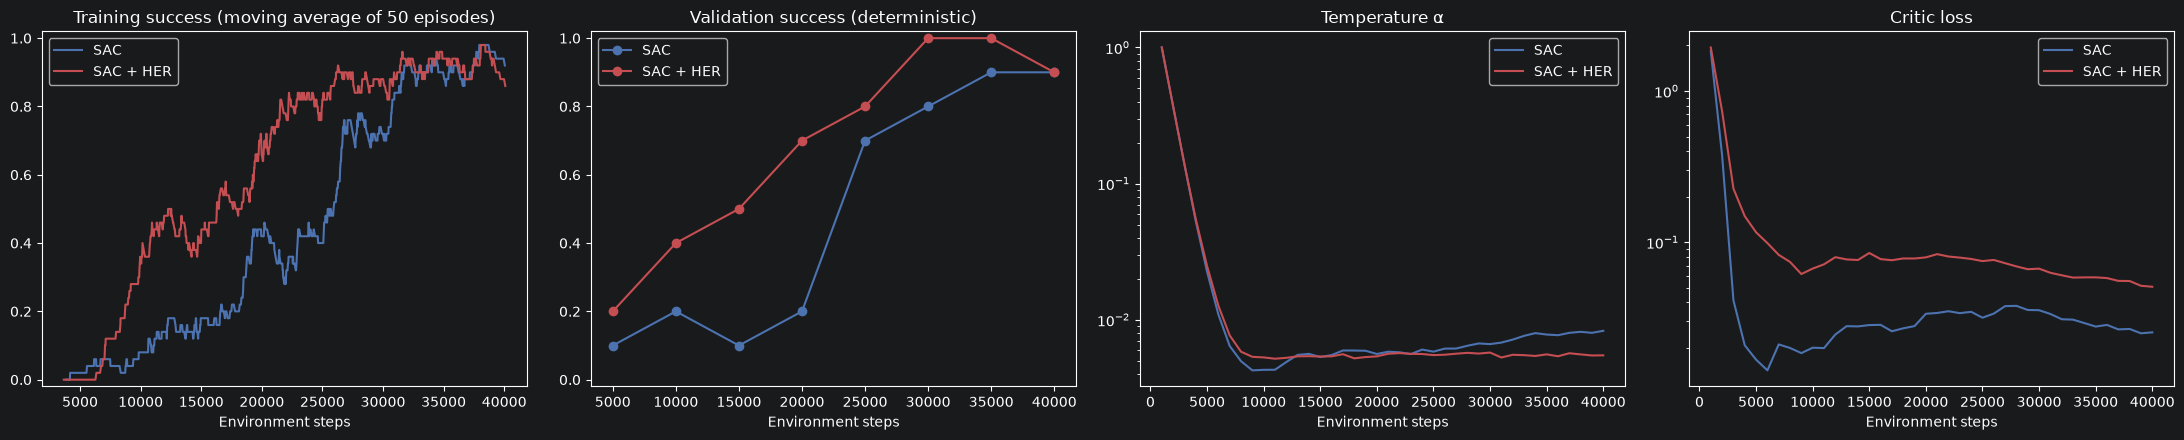

In [7]:
# --- LEARNING CURVES ---

# Moving average.
def moving_average(x, k=50):
    """Mean of the last k values (valid part only)."""

    # Convolution with a flat window.
    return np.convolve(x, np.ones(k) / k, mode="valid")


# Four panels.
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))

# Both runs.
for name, log, colour in [("SAC", sac_log, "#4C72B0"), ("SAC + HER", her_log, "#C44E52")]:

    # Smoothed training success.
    smooth = moving_average(np.array(log["success"]))

    # Plot against the step of the last episode of each window.
    axes[0].plot(np.array(log["episode_steps"])[len(log["episode_steps"]) - len(smooth):], smooth, color=colour, label=name)

    # Validation success.
    axes[1].plot(log["val_steps"], log["val_success"], marker="o", color=colour, label=name)

    # Temperature.
    axes[2].plot(log["alpha_steps"], log["alpha"], color=colour, label=name)

    # Critic loss.
    axes[3].plot(log["alpha_steps"], log["critic_loss"], color=colour, label=name)

# Titles.
for ax, title in zip(axes, ["Training success (moving average of 50 episodes)", "Validation success (deterministic)",
                            "Temperature α", "Critic loss"]):

    # Title.
    ax.set_title(title)

    # x label.
    ax.set_xlabel("Environment steps")

    # Legend.
    ax.legend()

# Success rates between 0 and 1.
axes[0].set_ylim(-0.02, 1.02)

# Same for validation.
axes[1].set_ylim(-0.02, 1.02)

# Logarithmic scale for α.
axes[2].set_yscale("log")

# And for the loss.
axes[3].set_yscale("log")

# Layout.
plt.tight_layout()

# Show.
plt.show()

## Step 7 — Test on the 50 scenarios

Both agents drive deterministically, with their best validation actor, on the same 50 scenarios as the baselines.

The chart shows how the episodes end: **parked**, **crash** (into a wall), or **time up** (still driving, or stopped in the wrong place).

random          return  -33.99 | success   0% | crash  84% | time 13.0 s | final distance 27.79 m | heading error  95.3 deg
standing still  return  -46.78 | success   0% | crash   0% | time 20.2 s | final distance 20.81 m | heading error  95.0 deg
v6 SAC          return   -9.06 | success  90% | crash   0% | time  6.3 s | final distance  2.14 m | heading error  12.6 deg
v6 SAC+HER      return   -8.45 | success  90% | crash   4% | time  5.7 s | final distance  1.86 m | heading error  12.3 deg


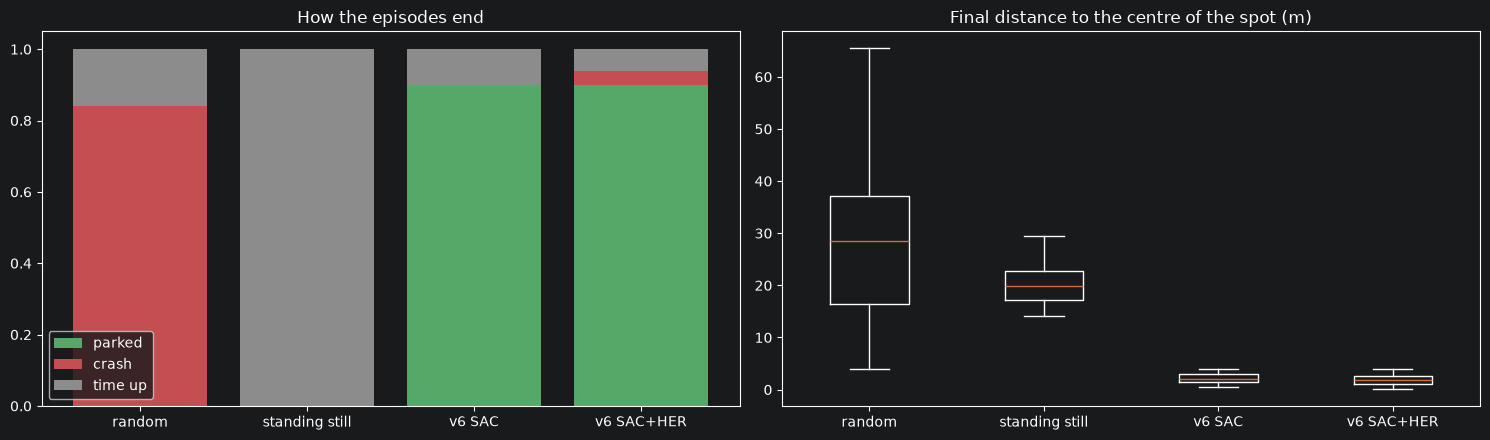


Saved results/parking_results.json


In [8]:
# --- TEST ---

# Plain SAC.
results["v6 SAC"] = evaluate(make_driver(sac_agent))

# SAC + HER.
results["v6 SAC+HER"] = evaluate(make_driver(her_agent))

# All drivers.
for name, res in results.items():

    # One line each.
    summary(name, res)

# Driver names in order.
names = list(results.keys())

# Share of episodes that ended in time up.
time_up = {n: 1 - results[n]["success"].mean() - results[n]["crash"].mean() for n in names}

# Two panels.
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Stacked outcomes.
bottom = np.zeros(len(names))

# Three outcomes.
for label, values, colour in [("parked", [results[n]["success"].mean() for n in names], "#55A868"),
                              ("crash", [results[n]["crash"].mean() for n in names], "#C44E52"),
                              ("time up", [time_up[n] for n in names], "#8C8C8C")]:

    # Stacked bar.
    axes[0].bar(names, values, bottom=bottom, color=colour, label=label)

    # Move the base up.
    bottom += np.array(values)

# Title.
axes[0].set_title("How the episodes end")

# Legend.
axes[0].legend()

# Final distance to the spot, one box per driver.
axes[1].boxplot([results[n]["distance"] for n in names])

# Driver names under the boxes.
axes[1].set_xticks(range(1, len(names) + 1), names)

# Title.
axes[1].set_title("Final distance to the centre of the spot (m)")

# Layout.
plt.tight_layout()

# Show.
plt.show()

# --- SAVE THE RESULTS ---

# Means of every driver.
parking_results = {n: {metric: float(values.mean()) for metric, values in res.items()} for n, res in results.items()}

# Write the file.
(RESULTS_DIR / "parking_results.json").write_text(json.dumps(parking_results, indent=2))

# Confirm.
print("\nSaved results/parking_results.json")

## Step 8 — Trajectories in the parking lot

The parking lot seen from above:
- 14 spots in the upper row and 14 in the lower row, each 4 m wide and 8 m deep;
- the walls (70 m × 42 m) around it.

For 8 test scenarios we draw the path of the SAC + HER car:
- the starting point is a circle, at the centre of the lot;
- the target spot is filled in the same colour as its path;
- the final position is a cross.

This shows the manoeuvres directly: curves, reversing, approaching the spot nose-first or tail-first. The y-axis points down, as in the simulator picture.

Then the GIFs of SAC + HER and of SAC alone on scenario 1000.

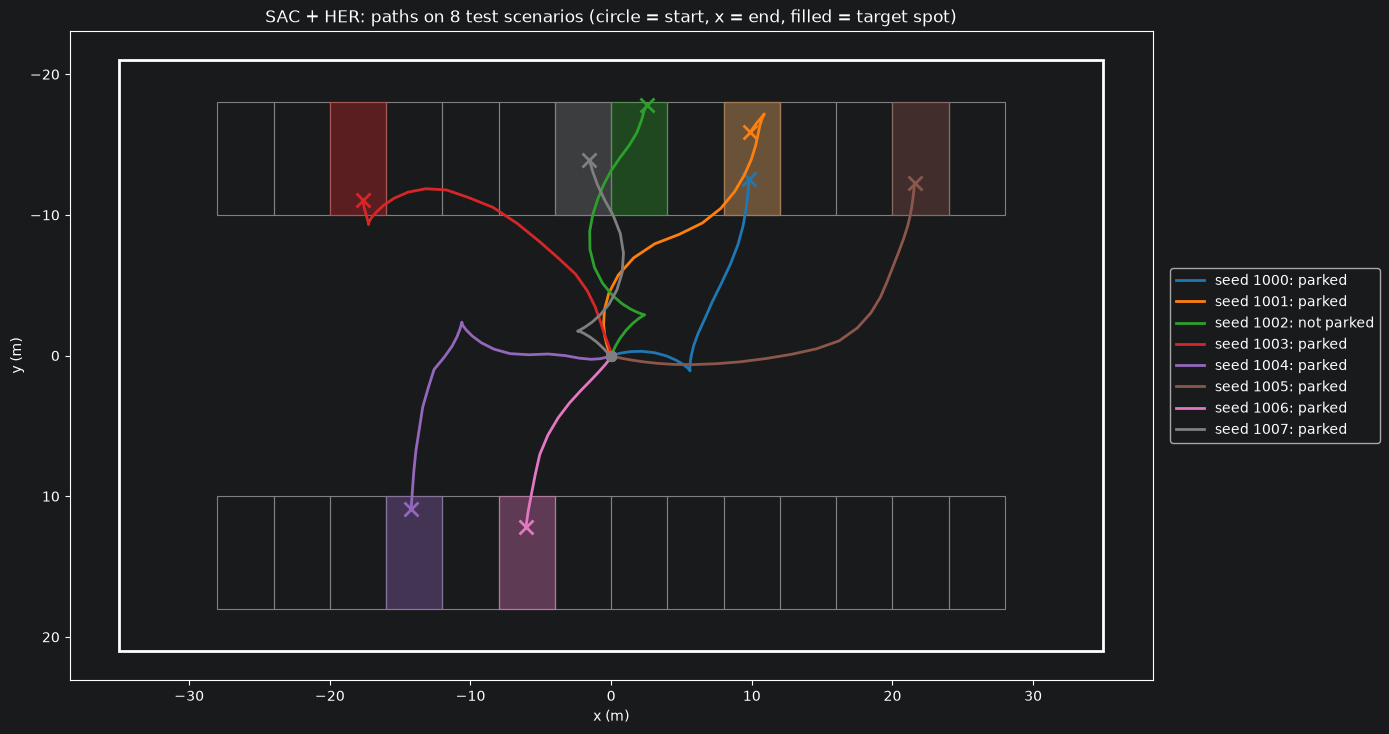

SAC + HER, scenario 1000: return -7.54, PARKED  (videos/v6_sac_her.gif)


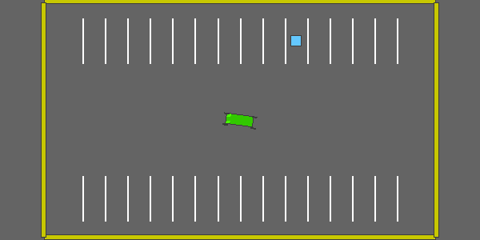

SAC alone, scenario 1000: return -7.83, PARKED  (videos/v6_sac.gif)


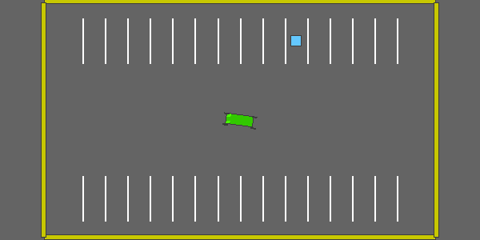

In [9]:
# --- TRAJECTORIES ---

# Play one scenario and record the positions.
def trajectory(driver, seed, env=env_eval):
    """Return (positions (T, 2), goal position (2,), parked)."""

    # Start.
    obs, info = env.reset(seed=seed)

    # Positions, starting with the initial one.
    positions = [env.unwrapped.vehicle.position.copy()]

    # Until the end.
    done = False

    # Play.
    while not done:

        # Step.
        obs, _, terminated, truncated, info = env.step(driver(env, obs))

        # Record the position.
        positions.append(env.unwrapped.vehicle.position.copy())

        # End?
        done = terminated or truncated

    # Path, goal and outcome.
    return np.array(positions), env.unwrapped.vehicle.goal.position.copy(), bool(info["is_success"])


# One large panel.
fig, ax = plt.subplots(figsize=(14, 8.5))

# Walls: a 70 m x 42 m rectangle centred at the origin.
ax.add_patch(Rectangle((-35, -21), 70, 42, fill=False, edgecolor="white", linewidth=2))

# The 14 columns of spots.
for k in range(14):

    # Centre x of the spot (same formula as the environment).
    x = (k + 1 - 14 // 2) * 4.0 - 2.0

    # Lower row (y from 10 to 18) and upper row (y from -18 to -10).
    for y0 in [10, -18]:

        # Outline of the spot.
        ax.add_patch(Rectangle((x - 2, y0), 4, 8, fill=False, edgecolor="gray", linewidth=0.8))

# The SAC + HER driver.
driver = make_driver(her_agent)

# Eight colours.
colours = plt.cm.tab10(np.arange(8))

# Eight test scenarios.
for seed, colour in zip(EVAL_SEEDS[:8], colours):

    # Record.
    path, goal, parked = trajectory(driver, seed)

    # Target spot, filled.
    ax.add_patch(Rectangle((goal[0] - 2, goal[1] - 4), 4, 8, color=colour, alpha=0.35))

    # The path.
    ax.plot(path[:, 0], path[:, 1], color=colour, linewidth=2, label=f"seed {seed}: {'parked' if parked else 'not parked'}")

    # Start.
    ax.plot(path[0, 0], path[0, 1], marker="o", color=colour, markersize=7)

    # End.
    ax.plot(path[-1, 0], path[-1, 1], marker="x", color=colour, markersize=10, markeredgewidth=2)

# Same scale on both axes.
ax.set_aspect("equal")

# The simulator draws y downwards.
ax.invert_yaxis()

# Labels.
ax.set_xlabel("x (m)")

# y label.
ax.set_ylabel("y (m)")

# Title.
ax.set_title("SAC + HER: paths on 8 test scenarios (circle = start, x = end, filled = target spot)")

# Legend outside the lot.
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))

# Layout.
plt.tight_layout()

# Show.
plt.show()

# SAC + HER on the usual scenario.
show_episode(make_driver(her_agent), seed=1000, filename="v6_sac_her.gif", title="SAC + HER, scenario 1000")

# SAC alone on the same scenario.
show_episode(make_driver(sac_agent), seed=1000, filename="v6_sac.gif", title="SAC alone, scenario 1000")

## Results and conclusions

### Test results (50 scenarios, deterministic driving)
| Driver | Return | Parked | Crash | Time | Final distance | Heading error |
|---|---|---|---|---|---|---|
| random | −33.99 | 0% | 84% | 13.0 s | 27.8 m | 95° |
| standing still | −46.78 | 0% | 0% | 20.2 s | 20.8 m | 95° |
| v6 SAC | −9.06 | **90%** | **0%** | 6.3 s | 2.14 m | 12.6° |
| **v6 SAC + HER** | **−8.45** | **90%** | 4% | **5.7 s** | **1.86 m** | **12.3°** |

### 1. Both agents learned to park
- Both agents park in **90%** of the scenarios, in about 6 seconds, starting from a random orientation.
- The trajectories show manoeuvres nobody programmed:
  - when the car starts facing the wrong way, it **reverses and turns** (the cusps in the paths of seeds 1002, 1003, 1004 and 1007);
  - then it enters the spot nose-first, as the goal orientation requires.

### 2. What HER adds: speed of learning
- With HER the agent learns much **earlier**:
  - training success reaches 50% after about 15,000 steps, against about 26,000 without HER;
  - at 20,000 steps the validation success is 70% with HER and 20% without.
- By 40,000 steps the two runs **converge** to the same test success.
- So HER saved roughly 40% of the experience needed. It did not make the impossible possible, because here the reward is **dense**: it grows with every metre of approach, so SAC alone also receives a useful signal.
- HER was designed for **sparse** rewards, for example −1 at every step until success. With that reward SAC alone would see almost no successes, and HER would be the difference between learning and not learning.
  - Changing the reward in `goal_reward` and in the environment would be an instructive extra experiment.

### 3. "Parked" according to the reward, not according to us
- The final distance from the centre of the spot is still about 2 m. Several paths (seeds 1003, 1005) end at the **entrance** of the spot, not in the middle.
- The reason is the reward weights: $x$ has weight 1, but $y$ (the depth of the spot) only 0.3.
  - Stopping 3 m short in $y$ costs as much as 0.9 m in $x$, which is still inside the success threshold.
  - The episode **ends at the first success**, so the car stops as soon as it is "good enough".
- As in v4 and v5: **the agent optimises exactly the reward we wrote.** A larger $y$ weight or a stricter threshold would make it park deeper.

### 4. Failures and model selection
- **Seed 1002** went too deep into the spot and ended past its centre, outside the threshold, and the time ran out.
- SAC + HER hit a wall in 2 test episodes (4%); SAC alone never did.
- SAC + HER had 100% on validation and 90% on the test. With only 10 validation scenarios, one episode is 10 points of success rate, so the selection cannot separate models that are this close.

### 5. Inside SAC
- **α** falls from 1 to about 0.005 in the first 8,000 steps, then stays stable. That small temperature is enough to keep the entropy at the target (−2) once the critic values are learned.
- **The critic loss is higher with HER.** The relabelled goals add many terminal "success" transitions and much more varied targets, so the regression is harder. This is not a problem: the critic loss is not the objective.

### 6. The whole project at a glance
| Task | Action | Best agent | Result |
|---|---|---|---|
| Highway (v1–v4) | 5 buttons, 1 Hz | Attention + Double + Dueling DQN | return 26.83 (rule-based 22.83) |
| Racetrack (v5) | continuous steering, 5 Hz | PPO | 80% laps finished (lane keeper 4%) |
| Parking (v6) | throttle + steering, goal-conditioned | SAC + HER | 90% parked, 5.7 s |

All algorithms were written from scratch in PyTorch, on the CPU.